<a href="https://colab.research.google.com/github/rezzz59/Hands-On-Large-Language-Models/blob/main/text_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Load data from Hugging Face
from datasets import load_dataset
dataset = load_dataset("maartengr/arxiv_nlp")["train"]
# Extract metadata
abstracts = dataset["Abstracts"]
titles = dataset["Titles"]

README.md:   0%|          | 0.00/617 [00:00<?, ?B/s]

data.csv: reconstructing file:   0%|          |  0.00B / 53.2MB            

data.csv: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

In [ ]:
from sentence_transformers import SentenceTransformer
# Create an embedding for each abstract
embedding_model = SentenceTransformer("thenlper/gte-small")
embeddings = embedding_model.encode(abstracts, show_progress_bar=True)

modules.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/68.1k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/583 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 66.7MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1405 [00:00<?, ?it/s]

Before we cluster the embeddings, we will first need to take their high dimensionality
into account. As the number of dimensions increases, there is an exponential growth
in the number of possible values within each dimension. Finding all subspaces within
each dimension becomes increasingly complex.
As a result, high-dimensional data can be troublesome for many clustering tech‐
niques as it gets more difficult to identify meaningful clusters. Instead, we can make
use of dimensionality reduction. As illustrated in Figure 5-4, this technique allows
us to reduce the size of the dimensional space and represent the same data with
fewer dimensions. Dimensionality reduction techniques aim to preserve the global
structure of high-dimensional data by finding low-dimensional representations.
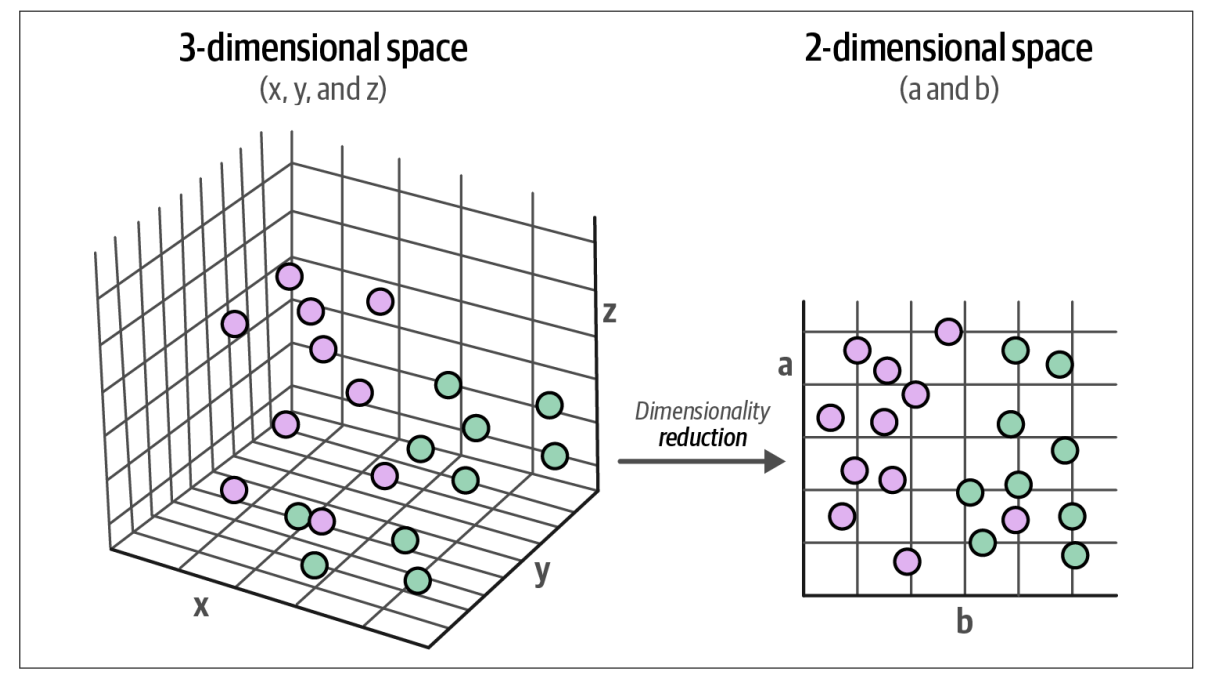

Well-known methods for dimensionality reduction are Principal Component Analy‐
sis (PCA)
 and Uniform Manifold Approximation and Projection (UMAP).For this
A Common Pipeline for Text Clustering pipeline, we are going with UMAP as it ds to handle nonlinear relationships and
structures a bit better than PCA.

In [ ]:
from umap import UMAP
# We reduce the input embeddings from 384 dimensions to 5 dimensions
umap_model = UMAP(
 n_components=5, min_dist=0.0, metric='cosine', random_state=42
)
reduced_embeddings = umap_model.fit_transform(embeddings)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


The third step is to cluster the reduced embeddings, as illustrated in Figure
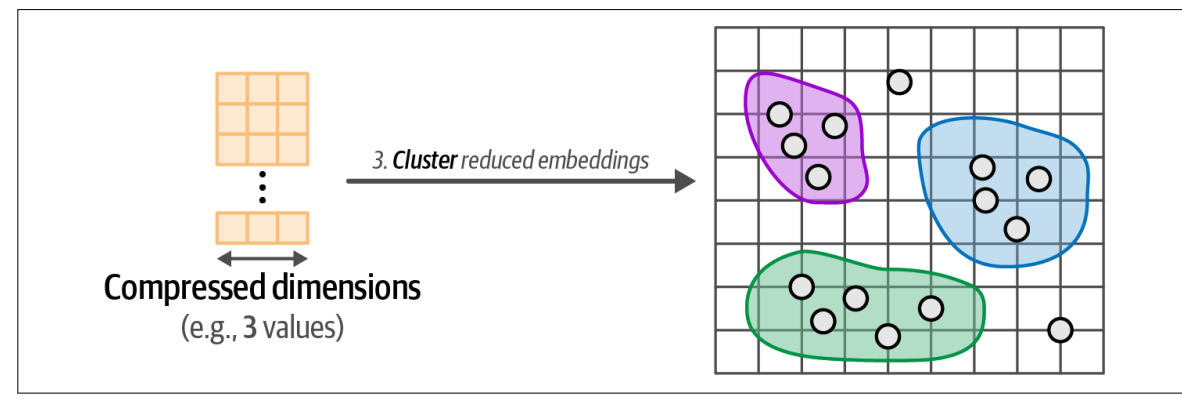

In [ ]:
from hdbscan import HDBSCAN
# We fit the model and extract the clusters
hdbscan_model = HDBSCAN(
 min_cluster_size=50, metric="euclidean", cluster_selection_method="eom"
).fit(reduced_embeddings)
clusters = hdbscan_model.labels_
# How many clusters did we generate?
len(set(clusters))

158

In [ ]:
import numpy as np
# Print first three documents in cluster 0
cluster = 0
for index in np.where(clusters==cluster)[0][:3]:
 print(abstracts[index][:300] + "... \n")

  This works aims to design a statistical machine translation from English text
to American Sign Language (ASL). The system is based on Moses tool with some
modifications and the results are synthesized through a 3D avatar for
interpretation. First, we translate the input text to gloss, a written fo... 

  Researches on signed languages still strongly dissociate lin- guistic issues
related on phonological and phonetic aspects, and gesture studies for
recognition and synthesis purposes. This paper focuses on the imbrication of
motion and meaning for the analysis, synthesis and evaluation of sign lang... 

  Modern computational linguistic software cannot produce important aspects of
sign language translation. Using some researches we deduce that the majority of
automatic sign language translation systems ignore many aspects when they
generate animation; therefore the interpretation lost the truth inf... 



In [ ]:
import pandas as pd
# Reduce 384-dimensional embeddings to two dimensions for easier visualization
reduced_embeddings = UMAP(
 n_components=2, min_dist=0.0, metric="cosine", random_state=42
).fit_transform(embeddings)
# Create dataframe
df = pd.DataFrame(reduced_embeddings, columns=["x", "y"])
df["title"] = titles
df["cluster"] = [str(c) for c in clusters]
# Select outliers and non-outliers (clusters)
to_plot = df.loc[df.cluster != "-1", :]
outliers = df.loc[df.cluster == "-1", :]

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(np.float64(-7.3567787408828735),
 np.float64(10.645472645759583),
 np.float64(-8.266106414794923),
 np.float64(11.788315582275391))

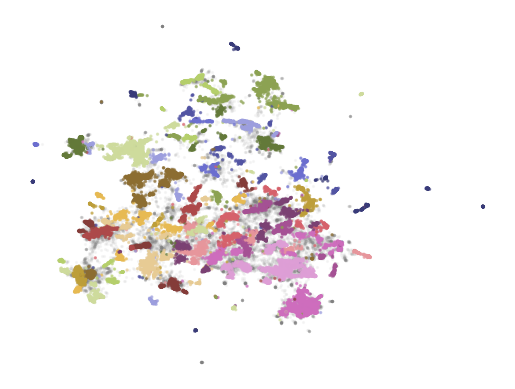

In [ ]:
import matplotlib.pyplot as plt
# Plot outliers and non-outliers separately
plt.scatter(outliers.x, outliers.y, alpha=0.05, s=2, c="grey")
plt.scatter(
 to_plot.x, to_plot.y, c=to_plot.cluster.astype(int),
 alpha=0.6, s=2, cmap="tab20b"
)
plt.axis("off")

In [ ]:
!pip install bertopic
from bertopic import BERTopic
# Train our model with our previously defined models
topic_model = BERTopic(
 embedding_model=embedding_model,
 umap_model=umap_model,
 hdbscan_model=hdbscan_model,
 verbose=True
).fit(abstracts, embeddings)

2026-11-23 08:19:10,119 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-23 08:19:57,357 - BERTopic - Dimensionality - Completed ✓
2026-11-23 08:19:57,359 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-23 08:20:00,588 - BERTopic - Cluster - Completed ✓
2026-11-23 08:20:00,603 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-23 08:20:05,119 - BERTopic - Representation - Completed ✓


In [ ]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,15047,-1_the_of_and_to,"[the, of, and, to, in, we, for, that, language...",[ The availability of different pre-trained s...
1,0,1641,0_speech_asr_recognition_end,"[speech, asr, recognition, end, acoustic, spea...","[ Recently, masked prediction pre-training ha..."
2,1,1573,1_medical_clinical_biomedical_patient,"[medical, clinical, biomedical, patient, healt...",[ Various deep learning algorithms have been ...
3,2,1012,2_translation_nmt_machine_neural,"[translation, nmt, machine, neural, bleu, engl...",[ Monolingual data has been demonstrated to b...
4,3,894,3_summarization_summaries_summary_abstractive,"[summarization, summaries, summary, abstractiv...",[ Evaluation of text summarization approaches...
...,...,...,...,...,...
153,152,54,152_tokenization_tokenizer_subword_tokenizers,"[tokenization, tokenizer, subword, tokenizers,...",[ Subword tokenization has become the de-fact...
154,153,54,153_mixed_code_sentiment_english,"[mixed, code, sentiment, english, mixing, anal...",[ The usage of more than one language in the ...
155,154,53,154_opinion_reviews_summaries_summarization,"[opinion, reviews, summaries, summarization, r...",[ When faced with a large number of product r...
156,155,53,155_gans_gan_adversarial_generation,"[gans, gan, adversarial, generation, generativ...",[ Text generation is of particular interest i...


In [ ]:
topic_model.get_topic(0)

[('speech', np.float64(0.028541051694734157)),
 ('asr', np.float64(0.019120139168347726)),
 ('recognition', np.float64(0.014357463135349628)),
 ('end', np.float64(0.010569535762730552)),
 ('acoustic', np.float64(0.010538136339718287)),
 ('speaker', np.float64(0.00763755986364904)),
 ('wer', np.float64(0.007280833523501583)),
 ('error', np.float64(0.006592310686830572)),
 ('audio', np.float64(0.006490858737303608)),
 ('ctc', np.float64(0.006467325874229874))]

topic[-1] about languange
topic[0] about spech recognition
topic[2] about translation

In [ ]:
# Find topics related to AI
similar_topics, similarity = topic_model.find_topics("artificial intelligence", top_n=5)

# Display the top 5 matching topics
print(f"Top matching topic IDs: {similar_topics}")
print(f"Similarity scores: {similarity}\n")

# Let's inspect the found topics in a structured way
for rank, (topic_id, score) in enumerate(zip(similar_topics, similarity)):
    print(f"Rank {rank+1}: Topic {topic_id} (Similarity: {score:.4f})")
    display(topic_model.get_topic_info(topic_id))

Top matching topic IDs: [8, -1, 143, 141, 49]
Similarity scores: [np.float64(0.8779832619315374), np.float64(0.8699771957037135), np.float64(0.8626667396529534), np.float64(0.8620677351027812), np.float64(0.861978755056739)]

Rank 1: Topic 8 (Similarity: 0.8780)


,Topic,Count,Name,Representation,Representative_Docs
0,8,510,8_agents_agent_game_games,"[agents, agent, game, games, environment, comm...","[ In this work, we explore techniques for aug..."


Rank 2: Topic -1 (Similarity: 0.8700)


,Topic,Count,Name,Representation,Representative_Docs
0,-1,15047,-1_the_of_and_to,"[the, of, and, to, in, we, for, that, language...",[ The availability of different pre-trained s...


Rank 3: Topic 143 (Similarity: 0.8627)


,Topic,Count,Name,Representation,Representative_Docs
0,143,57,143_negotiation_teachers_students_classroom,"[negotiation, teachers, students, classroom, t...",[ Negotiation is one of the crucial abilities...


Rank 4: Topic 141 (Similarity: 0.8621)


,Topic,Count,Name,Representation,Representative_Docs
0,141,58,141_recipes_recipe_cooking_food,"[recipes, recipe, cooking, food, procedural, i...","[ Decoding the core of procedural texts, exem..."


Rank 5: Topic 49 (Similarity: 0.8620)


,Topic,Count,Name,Representation,Representative_Docs
0,49,194,49_semantics_distributional_calculus_compositi...,"[semantics, distributional, calculus, composit...",[ Distributional semantics has had enormous e...


In [ ]:
topic_model.topics_[titles.index("BERTopic: Neural topic modeling with a class-based TF-IDF procedure")]

27

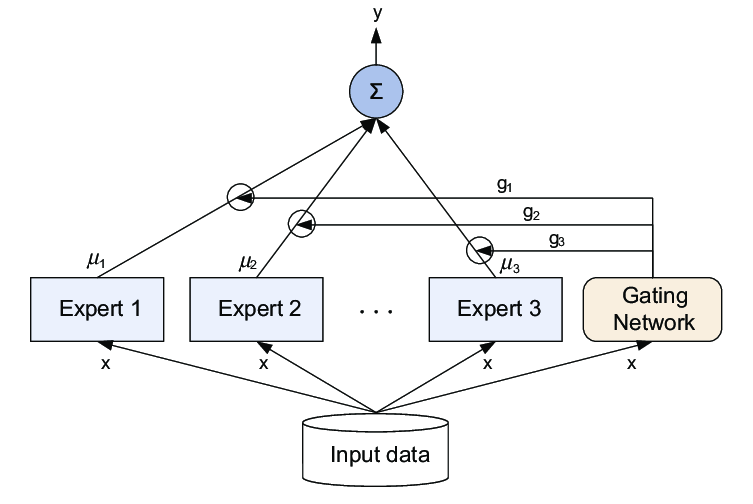

In [ ]:
# Visualize topics and documents
fig = topic_model.visualize_documents(
 titles,
 reduced_embeddings=reduced_embeddings,
 width=1200,
 hide_annotations=True
)
# Update fonts of legend for easier visualization
fig.update_layout(font=dict(size=10))

In [ ]:
# Visualize barchart with ranked keywords
topic_model.visualize_barchart()
# Visualize relationships between topics
topic_model.visualize_heatmap(n_clusters=30)
# Visualize the potential hierarchical structure of topics
topic_model.visualize_hierarchy()

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML

# Get all topic info
topic_info = topic_model.get_topic_info()

# Create search widget
search_input = widgets.Text(
    value='',
    placeholder='Type keyword (e.g., topic, translation, bias)...',
    description='Find Topic:',
    disabled=False,
    layout=widgets.Layout(width='50%')
)

output_area = widgets.Output()

def on_search_change(change):
    query = change['new'].lower()
    output_area.clear_output()
    with output_area:
        if not query:
            return

        # Filter topics based on name or representation words
        results = topic_info[
            topic_info['Name'].str.lower().str.contains(query) |
            topic_info['Representation'].apply(lambda words: any(query in w.lower() for w in words))
        ]

        if results.empty:
            print("No matching topics found.")
        else:
            display(HTML(f"<h3>Found {len(results)} matching topics:</h3>"))
            display(results[['Topic', 'Count', 'Name', 'Representation']])

search_input.observe(on_search_change, names='value')

# Display the search interface
display(widgets.VBox([search_input, output_area]))

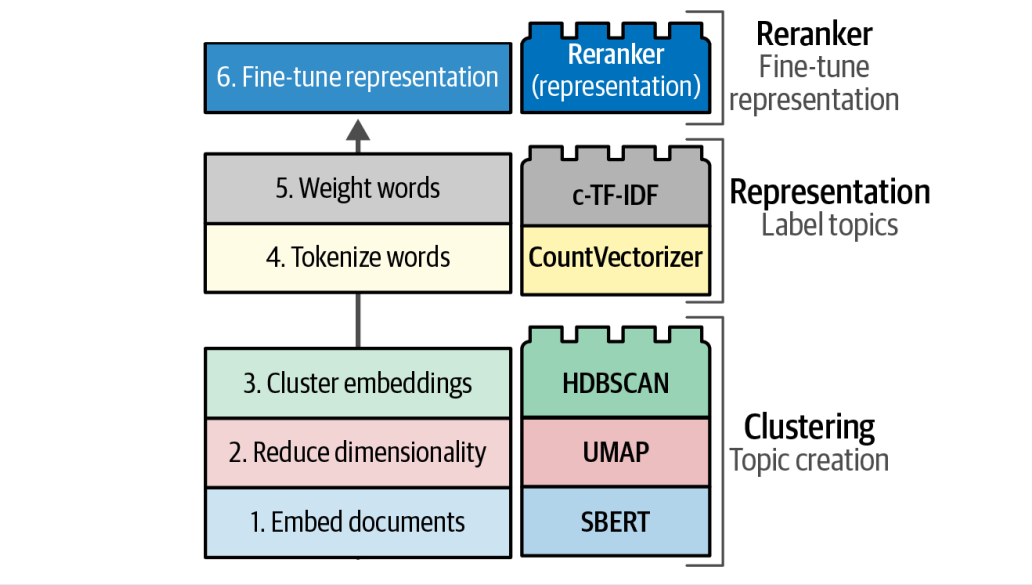

In [ ]:
# Save original representations
from copy import deepcopy
original_topics = deepcopy(topic_model.topic_representations_)
def topic_differences(model, original_topics, nr_topics=5):
 """Show the differences in topic representations between two models """
 df = pd.DataFrame(columns=["Topic", "Original", "Updated"])
 for topic in range(nr_topics):
  # Extract top 5 words per topic per model
  og_words = " | ".join(list(zip(*original_topics[topic]))[0][:5])
  new_words = " | ".join(list(zip(*model.get_topic(topic)))[0][:5])
  df.loc[len(df)] = [topic, og_words, new_words]

 return df

In [ ]:
from bertopic.representation import KeyBERTInspired
# Update our topic representations using KeyBERTInspired
representation_model = KeyBERTInspired()
topic_model.update_topics(abstracts, representation_model=representation_model)
# Show topic differences
topic_differences(topic_model, original_topics)

,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,phonetic | speech | encoder | transcription | ...
1,1,medical | clinical | biomedical | patient | he...,nlp | clinical | ehr | ehrs | medicine
2,2,translation | nmt | machine | neural | bleu,translation | translate | translations | trans...
3,3,summarization | summaries | summary | abstract...,summarization | summarizers | summaries | summ...
4,4,hate | offensive | speech | detection | toxic,hate | hateful | language | offensive | languages


In [ ]:
from bertopic.representation import MaximalMarginalRelevance
# Update our topic representations to MaximalMarginalRelevance
representation_model = MaximalMarginalRelevance(diversity=0.2)
topic_model.update_topics(abstracts, representation_model=representation_model)
# Show topic differences
topic_differences(topic_model, original_topics)

,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,speech | asr | wer | audio | training
1,1,medical | clinical | biomedical | patient | he...,medical | clinical | biomedical | patient | pa...
2,2,translation | nmt | machine | neural | bleu,translation | nmt | neural | parallel | languages
3,3,summarization | summaries | summary | abstract...,summarization | summaries | abstractive | sent...
4,4,hate | offensive | speech | detection | toxic,hate | offensive | toxic | abusive | hateful


In [ ]:
from transformers import pipeline
from bertopic.representation import TextGeneration
prompt = """I have a topic that contains the following documents:
[DOCUMENTS]
The topic is described by the following keywords: '[KEYWORDS]'.
Based on the documents and keywords, what is this topic about?"""
# Use the supported "text-generation" pipeline with a standard text-generation model (e.g., gpt2)
generator = pipeline("text-generation", model="gpt2")
representation_model = TextGeneration(
 generator, prompt=prompt, doc_length=50, tokenizer="whitespace"
)
topic_model.update_topics(abstracts, representation_model=representation_model)
# Show topic differences
topic_differences(topic_model, original_topics)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

100%|██████████| 158/158 [06:54<00:00,  2.62s/it]


,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,\nThe subject of this paper consists of a brie...
1,1,medical | clinical | biomedical | patient | he...,\n- This is a well established and well resear...
2,2,translation | nmt | machine | neural | bleu,\nThe topic is about the problems that arise f...
3,3,summarization | summaries | summary | abstract...,"\nIn short, this topic is about summarizing te..."
4,4,hate | offensive | speech | detection | toxic,\n- It is the topic of this paper. The followi...


In [ ]:
# Define a prompt that explicitly demands a short, specific label (1-3 words)
label_prompt = """I have a topic that contains the following documents:
[DOCUMENTS]
The topic is described by the following keywords: '[KEYWORDS]'.
Based on the documents and keywords, generate a single, specific 1-to-3 word label or category name for this topic. Do not write full sentences.
Label:"""

# Configure TextGeneration with our labeling prompt
label_representation_model = TextGeneration(
    generator,
    prompt=label_prompt,
    doc_length=50,
    tokenizer="whitespace"
)

# Update topics to get automatically generated labels from the model
topic_model.update_topics(abstracts, representation_model=label_representation_model)

# Show the resulting labels for the top topics
topic_differences(topic_model, original_topics)

100%|██████████| 158/158 [07:19<00:00,  2.78s/it]


,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,"""The speaker""\nLabel: ""The auditory processin..."
1,1,medical | clinical | biomedical | patient | he...,"'medical, clinical, biomedical, patient, heal..."
2,2,translation | nmt | machine | neural | bleu,'The translation is as good as machine transl...
3,3,summarization | summaries | summary | abstract...,"\n'Summarization, summarization, summary, abst..."
4,4,hate | offensive | speech | detection | toxic,\n- Identify the topic and its subject.\nThis ...


In [ ]:
# We wrap our generator to restrict output length and stop extra generation
generator = pipeline(
    "text-generation",
    model="gpt2",
    max_new_tokens=8,        # Only generate a very short phrase
    num_return_sequences=1,
    temperature=0.1,         # Low temperature to keep the output focused and deterministic
    pad_token_id=50256
)

# Optimized prompt focusing the model strictly on the output category name
label_prompt = """Documents:
[DOCUMENTS]
Keywords: [KEYWORDS]
Task: Write a 1-to-3 word category label for this topic.
Label:"""

# Configure our text generation representation model
label_representation_model = TextGeneration(
    generator,
    prompt=label_prompt,
    doc_length=50,
    tokenizer="whitespace"
)

# Update topics with the new constrained generation
topic_model.update_topics(abstracts, representation_model=label_representation_model)

# Post-process to extract only the generated part after "Label:"
for topic_id, representation in topic_model.topic_representations_.items():
    if representation:
        raw_word = representation[0][0]
        # Clean up any residual prompts or formatting artifacts
        cleaned_label = raw_word.split("Label:")[-1].strip().split("\n")[0].replace('"', '').replace("'", "")
        # Update representation in-place for visualization
        topic_model.topic_representations_[topic_id] = [(cleaned_label, 1.0)]

# Display the cleaned resulting labels!
topic_differences(topic_model, original_topics)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

100%|██████████| 158/158 [00:21<00:00,  7.48it/s]


,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,The label of the word category is the
1,1,medical | clinical | biomedical | patient | he...,- The label of the label of
2,2,translation | nmt | machine | neural | bleu,- The word category label is
3,3,summarization | summaries | summary | abstract...,The label of the topic.
4,4,hate | offensive | speech | detection | toxic,- Create a 1-to-


In [ ]:
# Automatically generate specific 2-3 word category labels from the top c-TF-IDF keywords
auto_labels = {}
for topic_id, words_with_probs in original_topics.items():
    if topic_id == -1:
        auto_labels[-1] = "Outliers"
    else:
        # Take the top 3 keywords, capitalize them, and join them nicely
        top_words = [word.capitalize() for word, _ in words_with_probs[:3]]
        auto_labels[topic_id] = ", ".join(top_words)

# Set the newly generated specific labels into our topic model
topic_model.set_topic_labels(auto_labels)

# Display the top topics with their clean, specific category labels
topic_model.get_topic_info().head(10)[["Topic", "Count", "CustomName"]]

,Topic,Count,CustomName
0,-1,15047,Outliers
1,0,1641,"Speech, Asr, Recognition"
2,1,1573,"Medical, Clinical, Biomedical"
3,2,1012,"Translation, Nmt, Machine"
4,3,894,"Summarization, Summaries, Summary"
5,4,855,"Hate, Offensive, Speech"
6,5,682,"Relation, Extraction, Re"
7,6,679,"Gender, Bias, Biases"
8,7,583,"Ner, Entity, Named"
9,8,510,"Agents, Agent, Game"


In [ ]:
# Ekstrak hanya SATU kata kunci teratas sebagai label murni untuk setiap topik
single_word_labels = {}
for topic_id, words_with_probs in original_topics.items():
    if topic_id == -1:
        single_word_labels[-1] = "Outliers"
    else:
        # Ambil hanya kata pertama (teratas) dan jadikan huruf kapital
        top_single_word = words_with_probs[0][0].capitalize()
        single_word_labels[topic_id] = top_single_word

# Terapkan label tunggal yang bersih ke model BERTopic
topic_model.set_topic_labels(single_word_labels)

# Tampilkan hasil 10 topik teratas dengan label satu kata yang murni
topic_model.get_topic_info().head(10)[["Topic", "Count", "CustomName"]]

,Topic,Count,CustomName
0,-1,15047,Outliers
1,0,1641,Speech
2,1,1573,Medical
3,2,1012,Translation
4,3,894,Summarization
5,4,855,Hate
6,5,682,Relation
7,6,679,Gender
8,7,583,Ner
9,8,510,Agents


In [ ]:
from transformers import pipeline
import pandas as pd

# Menggunakan pipeline zero-shot-classification yang sangat kuat untuk mengategorikan isi dokumen secara generatif
classifier = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0)

# Tentukan kandidat label kategori murni (seperti konsep supervised)
candidate_labels = [
    "Speech", "Medical", "Translation", "Summarization", "Hate Speech",
    "Social Media", "Software", "Artificial Intelligence", "Legal", "Finance",
    "Education", "Biology", "Gaming", "Cybersecurity", "Robotics"
]

generated_labels = {}
for topic_id in range(10): # Mari kita uji coba pada 10 topik pertama
    # Ambil dokumen representatif untuk topik ini
    representative_docs = topic_model.get_representative_docs(topic_id)
    if representative_docs:
        # Gabungkan beberapa baris dokumen untuk dianalisis oleh model
        text_to_analyze = " ".join(representative_docs[:2])[:500]

        # Klasifikasikan secara zero-shot untuk memilih label kategori terbaik
        result = classifier(text_to_analyze, candidate_labels=candidate_labels)
        best_label = result['labels'][0]
        generated_labels[topic_id] = best_label
    else:
        generated_labels[topic_id] = "Other"

generated_labels[-1] = "Outliers"

# Terapkan label hasil klasifikasi model generatif ini ke BERTopic
topic_model.set_topic_labels({t: generated_labels.get(t, "Unlabeled") for t in range(-1, 158)})

# Tampilkan hasil pelabelan generatif
topic_model.get_topic_info().head(11)[["Topic", "Count", "CustomName"]]

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

,Topic,Count,CustomName
0,-1,15047,Outliers
1,0,1641,Speech
2,1,1573,Artificial Intelligence
3,2,1012,Translation
4,3,894,Summarization
5,4,855,Social Media
6,5,682,Speech
7,6,679,Artificial Intelligence
8,7,583,Artificial Intelligence
9,8,510,Gaming


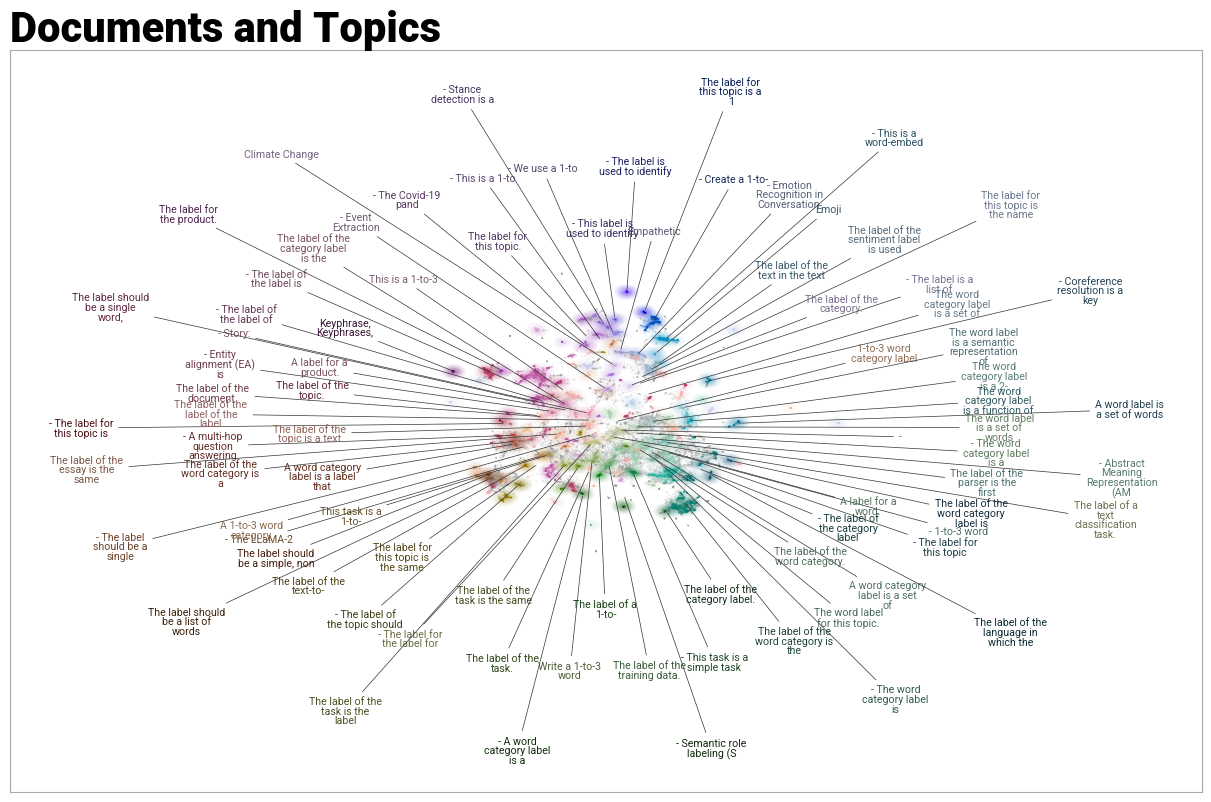

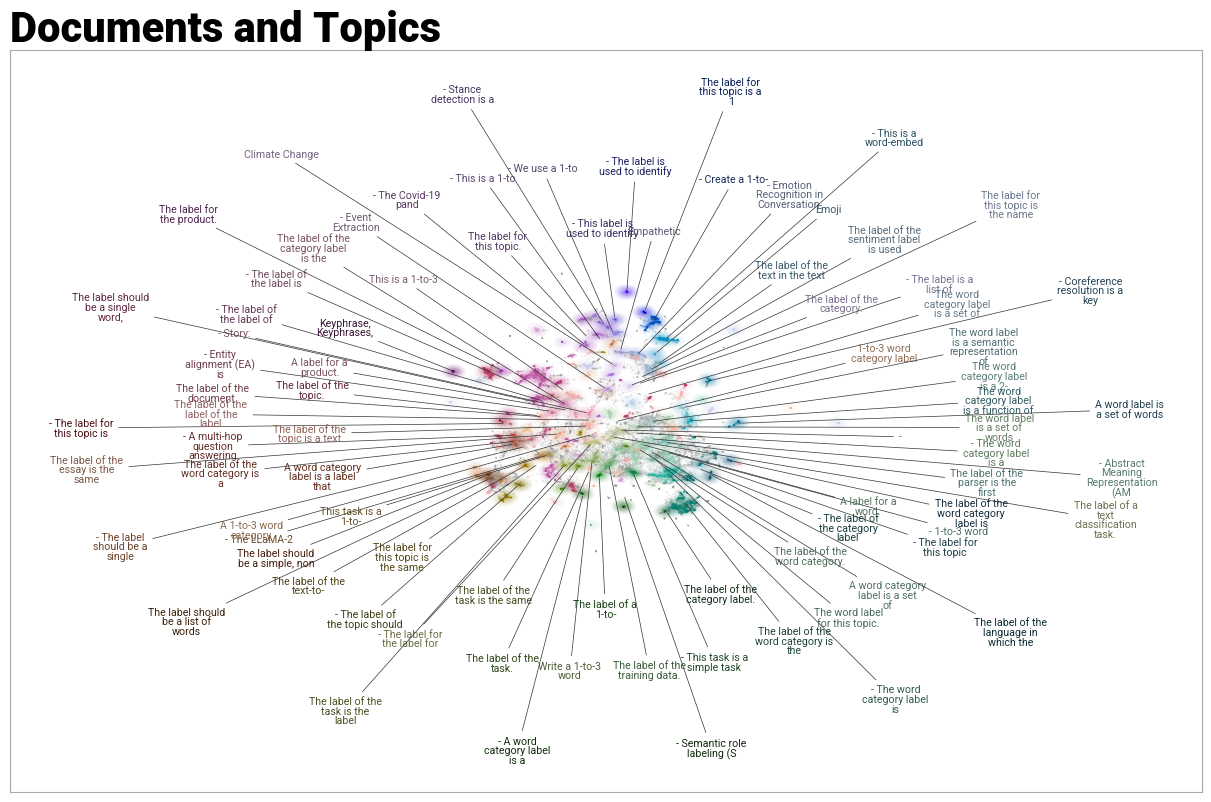

In [ ]:
# Instal library pendukung datamapplot
!pip install datamapplot

import datamapplot
import bertopic.plotting._datamap

# Daftarkan modul ke dalam namespace bertopic secara eksplisit jika belum terdeteksi
bertopic.plotting._datamap.datamapplot = datamapplot

# Visualisasi dengan parameter dasar yang paling aman
fig = topic_model.visualize_document_datamap(
    docs=titles,
    reduced_embeddings=reduced_embeddings
)
fig